In [88]:
#right hand coordinate

In [89]:
import math
import matplotlib.pyplot as plt
from vpython import vector, norm, mag , cross, dot
import pandas as pd
import numpy as np

In [90]:
ε = 1e-12  #10**(-12)  tolerance

def unit_vector(vec):  #若mag=0，计算norm时会坏掉
    vector_mag = mag(vec)

    if vector_mag < ε :
        output = vector(0,0,0)
    else:
        output = norm(vec)
    return output

In [91]:
def acceleration(v_ball, ω, v_wind, r, ρ, A, m, μ, g):
        v_mag_ball = mag(v_ball)
        v_rel = v_ball - v_wind
        v_rel_unit = unit_vector(v_rel)
    
        ω_gyro = dot( ω , v_rel_unit ) * v_rel_unit
        ω_active = ω - ω_gyro

        v_rel_mag = mag(v_rel)
        if v_rel_mag < ε :
            S = 0
        else:
            S = mag(ω_active) * r / v_rel_mag
    
        #CL = -3.25 * S**2 + 1.99 * S
        CL = max(0.0, -3.25 * S**2 + 1.99 * S)
    
        lift_direction = unit_vector( cross(ω_active , v_rel) ) 
        FL = 0.5 * ρ * A * CL * (mag(v_rel)**2) * lift_direction
        aL = FL / m 
        Re = (ρ * mag(v_rel) * (2*r)) / μ
        R = Re * (10**(-5))
        if 50000 <= Re <= 81200 :
            CD = 1.29*(R**2) - 2.59*R + 1.5
        elif Re > 81200 :
            CD = 0.191*(R**2) - 0.54*R + 0.56
        else:
            CD = 0.53
            
        FD = -( 0.5 * ρ * A * CD * (mag(v_rel)**2) * unit_vector(v_rel))
        aD = FD / m

        a_resultant = aD + g + aL

        return a_resultant , CD , Re

In [92]:
def spin_bounce(v, ω, R, m, e=0.75 , mu=0.35):
    I = 0.4*m*R**2
    n = vector(0,0,1)
    r_contact = -R*n
    contact_velocity = v + cross(ω, r_contact)
    ut = contact_velocity - dot(contact_velocity, n)*n
    Jn_mag = -m * (1 + e) * dot(v, n)
    Jn = Jn_mag*n
    Jtstick = (-2*m/7)*ut
    friction_limit = mu*Jn_mag

    if mag(Jtstick) <= friction_limit:
        Jt = Jtstick
    else:
        Jt = -friction_limit*unit_vector(ut)
    v_after = v + (Jn + Jt)/m
    omega_after = ω + cross(r_contact, Jt)/I
    
    return v_after, omega_after

In [93]:
def rk4_step(v_ball,x,ω,dt,v_wind,r,ρ,A,m,μ,g):   
        #k1v → v2 → k2v → v3 → k3v → v4 → k4v
        k1x = v_ball
        k1v = acceleration(v_ball=v_ball, ω=ω, v_wind=v_wind, r=r, ρ=ρ, A=A, m=m, μ=μ, g=g)[0]
        #预估1：
        v2 = v_ball + k1v * dt/2 #假设前半段加速度一直等于k1v。用起点加速度预估中点速度
        k2x = v2 #中点位置变化率
        k2v = acceleration(v2, ω*0.96**(dt/2), v_wind=v_wind, r=r, ρ=ρ, A=A, m=m, μ=μ, g=g)[0] #用预估1的中点速度计算中点加速度
        #预估2：
        v3 = v_ball + k2v * dt/2 #用中点加速度再次预估中点速度 反着来
        k3x = v3 #新中点位置变化率
        k3v = acceleration(v3, ω*0.96**(dt/2), v_wind=v_wind, r=r, ρ=ρ, A=A, m=m, μ=μ, g=g)[0] #用预估2的中点速度计算中点加速度

        v4 = v_ball + k3v * dt #用重新计算的中点加速度预估末点速度
        k4x = v4
        k4v = acceleration(v4, ω*0.96**(dt), v_wind=v_wind, r=r, ρ=ρ, A=A, m=m, μ=μ, g=g)[0] #用末点速度计算末点加速度

        x += (dt/6) * (k1x + 2*k2x + 2*k3x + k4x)
        v_ball += (dt/6) * (k1v + 2*k2v + 2*k3v + k4v)
    
        return x , v_ball

In [94]:
def projected_rolling_velocity(v, omega, R, k=0.4, n=vector(0,0,1)):
    vh = ( v - dot(v,n)*n ) * (1/(1+k))
    v_roll = vh + (R*k / (k+1)) * cross(omega,n)
    return v_roll

In [95]:
def horizontal_component(vec, n=vector(0,0,1)):
    return vec - dot(vec, n)*n

In [96]:
def rolling_omega(v_horizontal, R, n=vector(0,0,1)):
    return cross(n, v_horizontal) / R

In [97]:
def rolling_step(x, v, omega, R, g, dt, Crr=0.08, rest_speed=0.02):
    n = vector(0,0,1)
    v_horizontal = horizontal_component(v, n)
    speed = mag(v_horizontal)

    if speed <= rest_speed:
        x.z = R
        return x, vector(0,0,0), vector(0,0,0), True

    direction = unit_vector(v_horizontal)
    
    if Crr * mag(g) > 0:
        dt = min(dt, speed / (Crr * mag(g)))
    
    speed_after = max(0, speed - Crr*mag(g)*dt)
    average_speed = 0.5*(speed + speed_after)

    x = x + direction*average_speed*dt
    x.z = R
    v_after = direction*speed_after
    omega_after = rolling_omega(v_after, R, n)

    stopped = speed_after <= rest_speed
    if stopped:
        v_after = vector(0,0,0)
        omega_after = vector(0,0,0)
    return x, v_after, omega_after, stopped

In [98]:
def calculating_τ(v_ball, x, ω, dt, v_wind, r, ρ, A, m, μ, g, low, high, tol=1e-6): #bisection method
    τ = (low + high) / 2
    def test_height(τ):
        x_test, v_test = rk4_step(v_ball,x,ω, τ ,v_wind,r,ρ,A,m,μ,g)
        return x_test.z

    if test_height(low) < r or test_height(high) > r:
        raise ValueError('wrong bisection input')
        
    if abs(test_height(τ) - r) <= tol:
        return τ

    elif test_height(τ) - r < 0:
        high = τ
        return calculating_τ(v_ball, x, ω, dt, v_wind, r, ρ, A, m, μ, g, low=low, high=high, tol=tol)
    elif test_height(τ) - r > 0:
        low = τ
        return calculating_τ(v_ball, x, ω, dt, v_wind, r, ρ, A, m, μ, g, low=low, high=high, tol=tol)

In [99]:
def simulate_projectile(θ_deg = 45 ,
                        φ_deg = 20 ,  
                        s_initial = 40 , 
                        rpm = 10000 , 
                        spin_axis = vector(1,-1,0) ,  
                        v_wind = vector(0,0,0) ,
                        ρ = 1.225 , 
                        A = 0.00143 , 
                        r = 0.0213 ,
                        m = 0.04593 ,
                        μ = 1.8 * (10**(-5)) , #空气的动力黏度 Pa*s
                        e = 0.8 , 
                        g = vector(0,0,-9.81) ,
                        dt = 0.005,
                        Crr = 0.20, min_bounce_speed = 0.6,
                        rest_speed = 0.2, inertia_factor = 0.4):
    trajectory_data = []

    θ = math.radians(θ_deg)
    φ = math.radians(φ_deg)
    v_ball = vector(s_initial*math.cos(θ)*math.cos(φ),s_initial*math.cos(θ)*math.sin(φ),s_initial*math.sin(θ))
    ω = (rpm * (2*math.pi / 60)) * unit_vector(spin_axis)
    x = vector(0,0,r)
    t = 0


    a_now, CD_now, Re_now = acceleration(v_ball=v_ball, ω=ω, v_wind=v_wind, r=r, ρ=ρ, A=A, m=m, μ=μ, g=g)

    
    trajectory_data.append([t, x.x, x.y, x.z , CD_now , Re_now ]) #initial append


    state = 'flight'
    for i in range(1,200000):
        if state == 'rest':
            break

        a_now, CD_now, Re_now = acceleration(v_ball=v_ball, ω=ω, v_wind=v_wind, r=r, ρ=ρ, A=A, m=m, μ=μ, g=g)

        if state == 'rolling':
            x, v_ball, ω, stopped = rolling_step(x, v_ball, ω, r, g, dt, Crr=Crr, rest_speed=rest_speed)
            t += dt
            state = 'rest' if stopped else 'rolling'

            _, CD_now, Re_now = acceleration(v_ball, ω, v_wind, r, ρ, A, m, μ, g)#
            trajectory_data.append([t, x.x, x.y, x.z , CD_now , Re_now])
            continue

        x_next , v_ball_next = rk4_step(v_ball=v_ball,x=x,ω=ω,dt=dt,v_wind=v_wind, r=r, ρ=ρ, A=A, m=m, μ=μ, g=g)

        if x_next.z < r:
            if x.z == r and (v_ball.z < 0 or (v_ball.z==0 and a_now.z<=0)):
                τ=0
            else:
                τ = calculating_τ(v_ball, x, ω, dt, v_wind, r, ρ, A, m, μ, g,low=0, high=dt, tol=1e-6)
                
            x_next , v_ball_next = rk4_step(v_ball=v_ball,x=x,ω=ω,dt=τ,v_wind=v_wind, r=r, ρ=ρ, A=A, m=m, μ=μ, g=g)
            x = x_next
            x.z = r
            v_ball = v_ball_next
            t += τ
            ω = ω * 0.96**τ

            #contact
            v_bounce, ω = spin_bounce(v_ball, ω=ω, R=r, m=m, e=e)
            v_ball = v_bounce
            if abs(v_ball.z) < min_bounce_speed:
                v_ball.z = 0
                state = 'rolling'
                v_ball = projected_rolling_velocity(v_ball, ω, r, k=inertia_factor)
                ω = rolling_omega(v_ball, r)
            else:
                state = 'flight'

        else:
            x = x_next
            v_ball = v_ball_next
            t += dt
            ω = ω * 0.96**dt

        _,CD_now, Re_now = acceleration(v_ball, ω, v_wind, r, ρ, A, m, μ, g)#
        trajectory_data.append([t, x.x, x.y, x.z , CD_now , Re_now])

    return pd.DataFrame(trajectory_data,columns=['t','x','y','z','CD_now','Re_now']) 


In [100]:
#converting positions into yards for ploting
data = simulate_projectile()
def data_in_yards(data):
    x_data_yards = [ i * 1.09361 for i in data.x]
    y_data_yards = [ i * 1.09361 for i in data.y]
    z_data_yards = [ i * 1.09361 for i in data.z]

    return x_data_yards,y_data_yards,z_data_yards

x_yards_catch,y_yards_catch,z_yards_catch = data_in_yards(data)

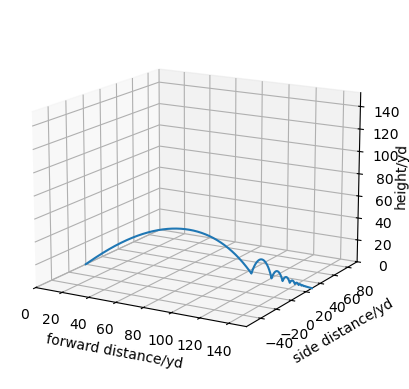

In [101]:
fig1 = plt.figure()
ax1=plt.axes(projection='3d')
x_yards_catch,y_yards_catch,z_yards_catch = data_in_yards(data)
    
ax1.plot3D(x_yards_catch,y_yards_catch,z_yards_catch)

x_min, x_max = min(x_yards_catch), max(x_yards_catch)
y_min, y_max = min(y_yards_catch), max(y_yards_catch)
z_min, z_max = min(z_yards_catch), max(z_yards_catch)

x_range = x_max - x_min
y_range = y_max - y_min
z_range = z_max - z_min

max_range = max(x_range , y_range , z_range)

y_mid = (y_max + y_min) / 2

ax1.set_xlim(0 , max_range)
ax1.set_ylim(y_mid - max_range/2, y_mid + max_range/2)
ax1.set_zlim(0 , max_range)

ax1.set_xlabel('forward distance/yd')
ax1.set_ylabel('side distance/yd')
ax1.set_zlabel('height/yd', labelpad = -2)

#
ax1.view_init(elev=15 , azim=300, roll=0 , vertical_axis='z')

plt.show()

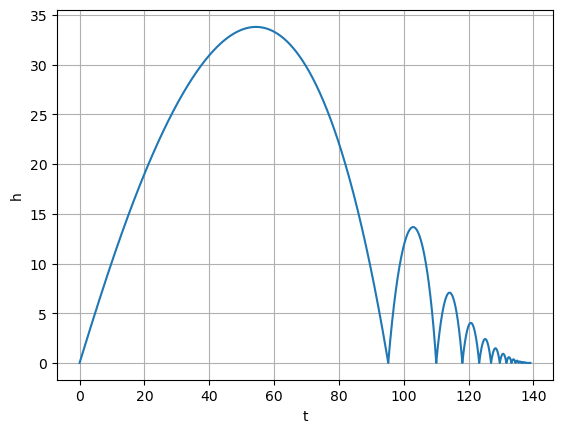

In [102]:
data = simulate_projectile()
plt.plot(data.x,data.z)
plt.xlabel('t')
plt.ylabel('h')
plt.grid()
plt.show()

C:\Users\90712\AppData\Local\Temp\ipykernel_25676\3153421222.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend()


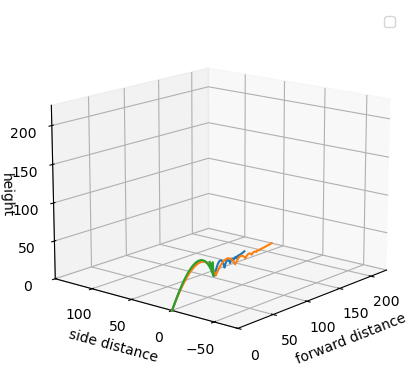

In [103]:
spinaxis_to_test = [vector(0,0,0),vector(0,1,0),vector(0,-1,0)]
fig1 = plt.figure()
ax1=plt.axes(projection='3d')

#
all_x = []
all_y = []
all_z = []

for axis in spinaxis_to_test:
    data = simulate_projectile(spin_axis=axis)
    x_yards_catch,y_yards_catch,z_yards_catch = data_in_yards(data)
    ax1.plot3D(x_yards_catch,y_yards_catch,z_yards_catch)

    all_x += x_yards_catch
    all_y += y_yards_catch
    all_z += z_yards_catch
    
x_min, x_max = min(all_x), max(all_x)
y_min, y_max = min(all_y), max(all_y)
z_min, z_max = min(all_z), max(all_z)

x_range = x_max - x_min
y_range = y_max - y_min
z_range = z_max - z_min

max_range = max(x_range, y_range, z_range)

y_mid = (y_max + y_min) / 2

ax1.set_xlim(0 , max_range)
ax1.set_ylim(y_mid - max_range/2, y_mid + max_range/2)
ax1.set_zlim(0 , max_range)


ax1.set_xlabel('forward distance')
ax1.set_ylabel('side distance')
ax1.set_zlabel('height', labelpad = -2)

#
ax1.view_init(elev=15 , azim=220 , roll=0 , vertical_axis='z')
ax1.legend()


plt.show()

In [104]:
simulate_projectile(θ_deg = 0.01,rpm=0,ρ = 0)

,t,x,y,z,CD_now,Re_now
0,0.000000,0.000000,0.000000,0.0213,0.53,0.0
1,0.001406,0.052858,0.019239,0.0213,0.53,0.0
2,0.006406,0.187076,0.068090,0.0213,0.53,0.0
3,0.011406,0.321249,0.116925,0.0213,0.53,0.0
4,0.016406,0.455376,0.165743,0.0213,0.53,0.0
...,...,...,...,...,...,...
2890,14.446406,195.528428,71.166528,0.0213,0.53,0.0
2891,14.451406,195.529487,71.166913,0.0213,0.53,0.0
2892,14.456406,195.530500,71.167282,0.0213,0.53,0.0
2893,14.461406,195.531467,71.167634,0.0213,0.53,0.0


In [105]:
#calculating_τ(
    v_ball=vector(0, 0, -1), x=vector(0, 0, -1),
    ω=vector(0, 0, 0), dt=0.005, v_wind=vector(0, 0, 0),
    r=0.0213, ρ=0, A=0.00143, m=0.04593, μ=1.8e-5,
    g=vector(0, 0, -9.81), low=0, high=0.005
)

IndentationError: unexpected indent (929975964.py, line 2)